<a href="https://colab.research.google.com/github/sam098761212-glitch/Leeseungsoo-AI_CLASS/blob/main/car_data_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [7]:
cols = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'label']
df = pd.read_csv('car.data', header=None, names=cols, na_values=['?'])

print(df.head())
print('결측치 개수:')
print(df.isnull().sum())

df = df.dropna()
print('결측치 삭제 후 행 개수:', len(df))

  buying  maint doors persons lug_boot safety  label
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc
결측치 개수:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
label       0
dtype: int64
결측치 삭제 후 행 개수: 1728


label
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


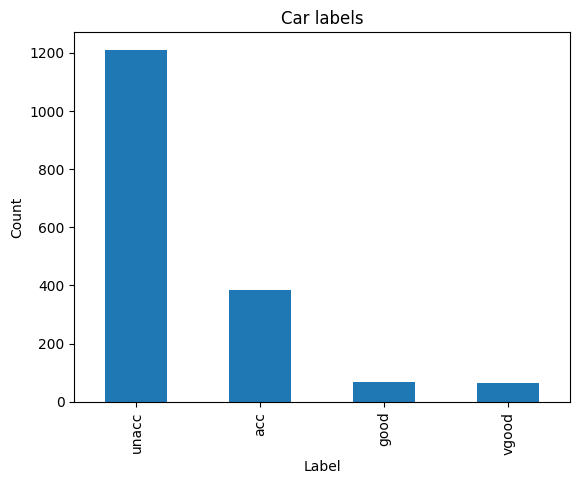

In [8]:
print(df['label'].value_counts())
df['label'].value_counts().plot(kind='bar', title='Car labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()


In [9]:
# 자동차 특성은 원-핫 인코딩
X = pd.get_dummies(df.drop(columns='label')).astype('float32')

# 자동차 등급을 0, 1, 2, 3으로 변환
y = df['label'].map({'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3})

X_train, X_test, y_train, y_test = train_test_split(
    X.to_numpy(), y.to_numpy(), test_size=0.2, random_state=42, stratify=y
)
print('학습 데이터:', X_train.shape, '테스트 데이터:', X_test.shape)


학습 데이터: (1382, 21) 테스트 데이터: (346, 21)


In [10]:
# Classification

model_cls = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(4, activation='softmax')
])
model_cls.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cls.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)

loss, accuracy = model_cls.evaluate(X_test, y_test, verbose=0)
print('분류 정확도:', round(accuracy, 4))



분류 정확도: 0.9133


In [11]:
# Regression

model_reg = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1)
])
model_reg.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_reg.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)

mse, mae = model_reg.evaluate(X_test, y_test, verbose=0)
print('회귀 MAE:', round(mae, 4))
print('회귀 MSE:', round(mse, 4))


회귀 MAE: 0.2145
회귀 MSE: 0.0924
